# Chapter 9

Python version of the R code for Chapter 9 of *In All Likelihood* (Pawitan, 2001).

Random numbers are generated with numpy, so simulated results will not
match the R output exactly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats, special

from helpers import DATA, qqnorm, qqline

## Figure 9.1 (`FIG9-1.R`)

Central limit theorem.

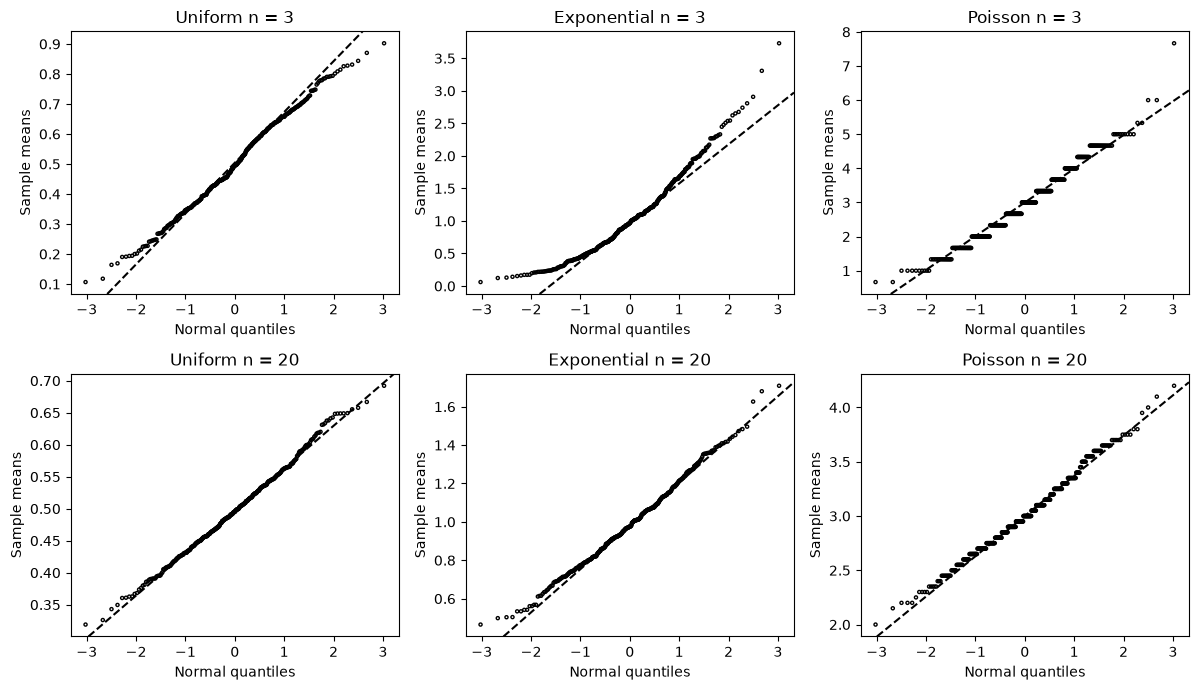

In [2]:
rng = np.random.default_rng(13)
nn = [3, 20]
nrep = 400

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for i, dist in enumerate(["Uniform", "Exponential", "Poisson"]):
    for j, n in enumerate(nn):
        if dist == "Uniform":
            x = rng.uniform(size=(nrep, n))
        if dist == "Exponential":
            x = rng.exponential(size=(nrep, n))
        if dist == "Poisson":
            x = rng.poisson(3, size=(nrep, n))
        xmean = x.mean(axis=1)
        ax = axes[j, i]
        q, s = qqnorm(xmean)
        qqline(ax, xmean, color="k", ls="--")
        ax.scatter(q, s, s=5, facecolors="none", edgecolors="k")
        ax.set_xlabel("Normal quantiles")
        ax.set_ylabel("Sample means")
        ax.set_title(f"{dist} n = {n}")
fig.tight_layout()
plt.show()

## Figure 9.2 (`FIG9-2.R`)

Variations of score statistics.

Mean of I(theta=4)= 2.5404197674475717 (theory=10/4=2.5)


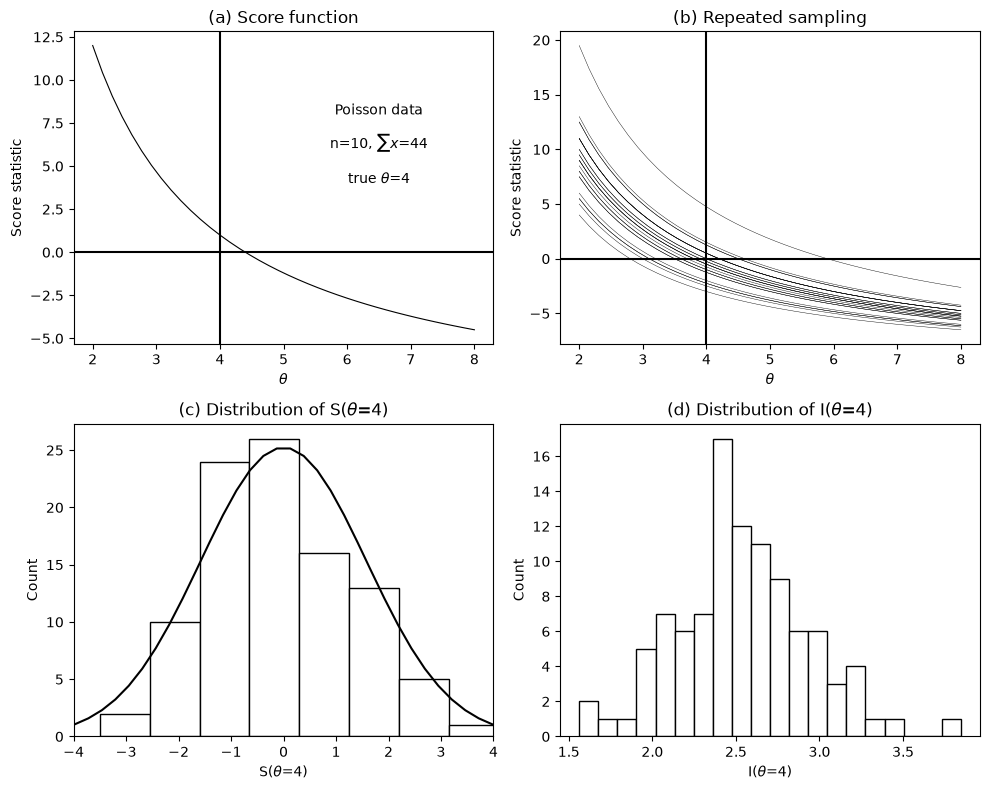

In [3]:
rng = np.random.default_rng(13)
n = 10
t0 = 4
x = rng.poisson(t0, size=n)

theta = np.linspace(t0 / 2, t0 * 2, 40)
stheta = -n + x.sum() / theta

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
ax.plot(theta, stheta, "k-", lw=0.8)
ax.text(6.5, 4., r"true $\theta$=4", ha="center")
ax.text(6.5, 6., rf"n=10, $\sum x$={x.sum()}", ha="center")
ax.text(6.5, 8, "Poisson data", ha="center")
ax.axvline(t0, color="k")
ax.axhline(0, color="k")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Score statistic")
ax.set_title("(a) Score function")

ax = axes[1]
for i in range(25):
    x = rng.poisson(t0, size=n)
    stheta = -n + x.sum() / theta
    ax.plot(theta, stheta, "k-", lw=0.3)
ax.axvline(t0, color="k")
ax.axhline(0, color="k")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Score statistic")
ax.set_title("(b) Repeated sampling")

x = rng.poisson(t0, size=(100, n))
sumx = x.sum(axis=1)
xbar = sumx / n

s0 = -n + sumx / t0
s2 = n / xbar  # Fisher information

ax = axes[2]
ax.hist(s0, bins=10, color="w", edgecolor="k")
ax.set_xlim(-4, 4)
y = np.linspace(-5, 5, 40)
ax.plot(y, 100 * stats.norm.pdf(y, 0, np.sqrt(10 / t0)), "k-")
ax.set_xlabel(r"S($\theta$=4)")
ax.set_ylabel("Count")
ax.set_title(r"(c) Distribution of S($\theta$=4)")

ax = axes[3]
ax.hist(s2, bins=20, color="w", edgecolor="k")
ax.set_xlabel(r"I($\theta$=4)")
ax.set_ylabel("Count")
ax.set_title(r"(d) Distribution of I($\theta$=4)")
print("Mean of I(theta=4)=", s2.mean(), "(theory=10/4=2.5)")

fig.tight_layout()
plt.show()

## Figure 9.5 (`FIG9-5.R`)

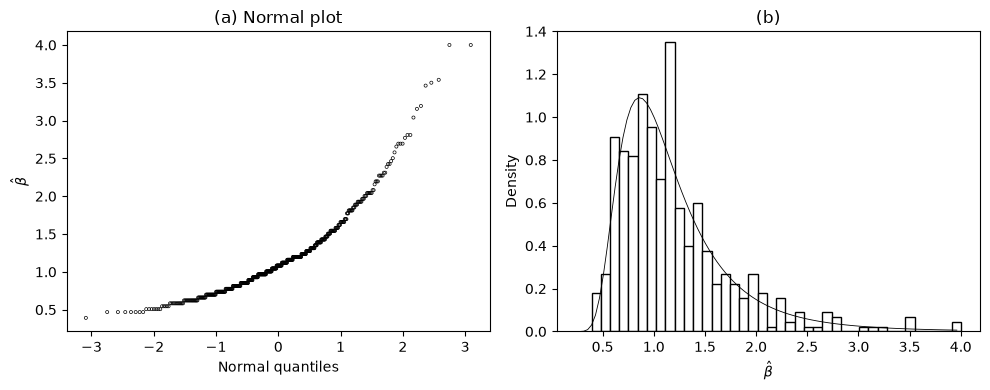

In [4]:
n = 10
mu = 1
th = np.linspace(.2, 4, 100)

nrep = 500
est = []
rng = np.random.default_rng(5)
for i in range(nrep):
    x = -mu * np.log(rng.uniform(size=n))
    ll = -n * th * np.log(mu) - n * np.log(special.gamma(th)) + (th - 1) * np.sum(np.log(x))
    ll = np.exp(ll - ll.max())
    ll = ll / ll.sum() / (th[1] - th[0])

    ll = (n * th * np.log(th / mu) + (th - 1) * np.sum(np.log(x))
          - th * np.sum(x) / mu - n * np.log(special.gamma(th)))
    ll = np.exp(ll - ll.max())
    est.append(th[ll == ll.max()].min())
est = np.array(est)

# .................................. saddlepoint approx
h = th[1] - th[0]
lg_th = np.log(special.gamma(th))
dgamma = (lg_th[2:] - lg_th[:-2]) / 2 / h  # first derivative of log gamma
d2gamma = np.diff(lg_th, n=2) / h ** 2     # second derivative of log gamma
ths = th[1:99]
lg = (n * np.log(special.gamma(ths)) + 0.5 * np.log(d2gamma - 1 / ths)
      - n * ((ths - 1) * dgamma + 1 * np.log(ths) - ths))
gtheta = np.exp(lg - lg.max())
gtheta = gtheta / gtheta.sum() / h  # normalizing

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
q, s = qqnorm(est)
ax.scatter(q, s, s=5, facecolors="none", edgecolors="k", lw=0.5)
ax.set_xlabel("Normal quantiles")
ax.set_ylabel(r"$\hat\beta$")
ax.set_title("(a) Normal plot")

ax = axes[1]
ax.hist(est, bins=40, density=True, color="w", edgecolor="k")
ax.set_ylim(0, 1.4)
ax.plot(ths, gtheta, "k-", lw=0.6)  # magic formula
ax.set_xlabel(r"$\hat\beta$")
ax.set_ylabel("Density")
ax.set_title("(b)")
fig.tight_layout()
plt.show()

## Figure 9.6 (`FIG9-6.R`)

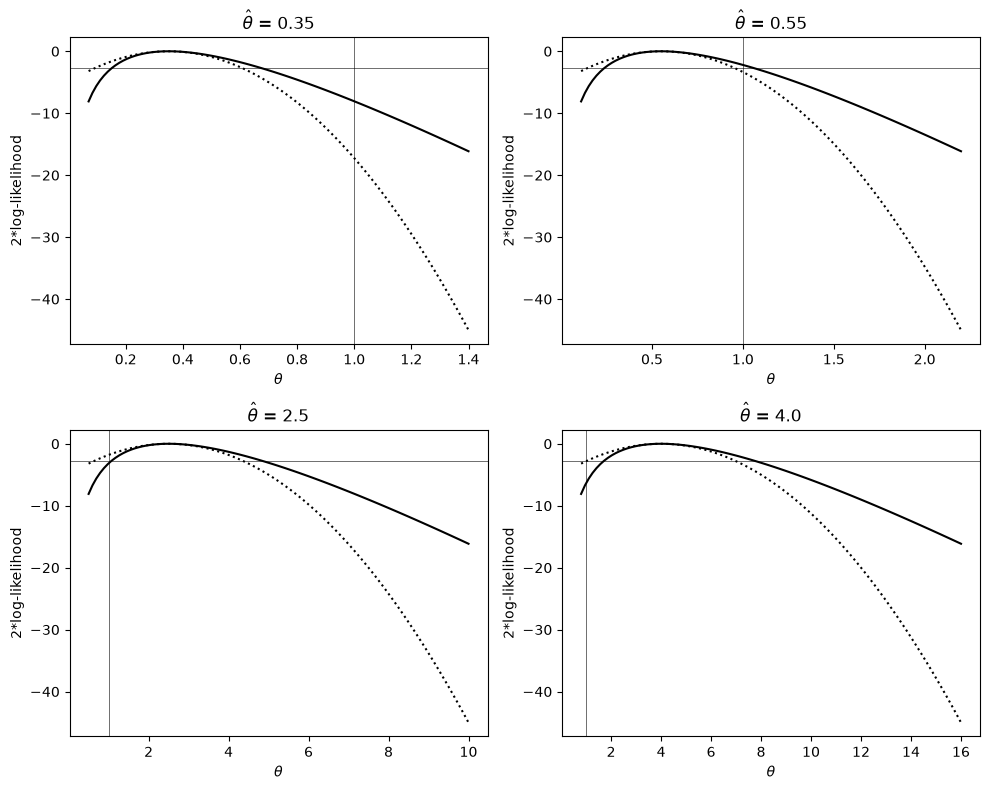

In [5]:
n = 5
est = [.35, .55, 2.5, 4.0]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, that in zip(axes.ravel(), est):
    sumx = n / that
    th = np.linspace(that / 5, that * 4, 100)
    lt = -th * n / that + n * np.log(th)
    lt = 2 * (lt - lt.max())
    ax.plot(th, lt, "k-")
    ax.axvline(1, color="k", lw=0.4)
    ax.axhline(-stats.chi2.ppf(.9, 1), color="k", lw=0.4)

    # normal approx
    ihat = n / that ** 2
    nl = -ihat * (that - th) ** 2
    ax.plot(th, nl, "k:", lw=1.5)
    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel("2*log-likelihood")
    ax.set_title(rf"$\hat\theta$ = {that}")
fig.tight_layout()
plt.show()

## Figure 9.7 (`FIG9-7.R`)

One-way random effects, from Amstat Aug 96, page 226.

0.24241642868939933 0.45162512742134664
0.5126195240997694 6.571497510334543
3.046054808453496


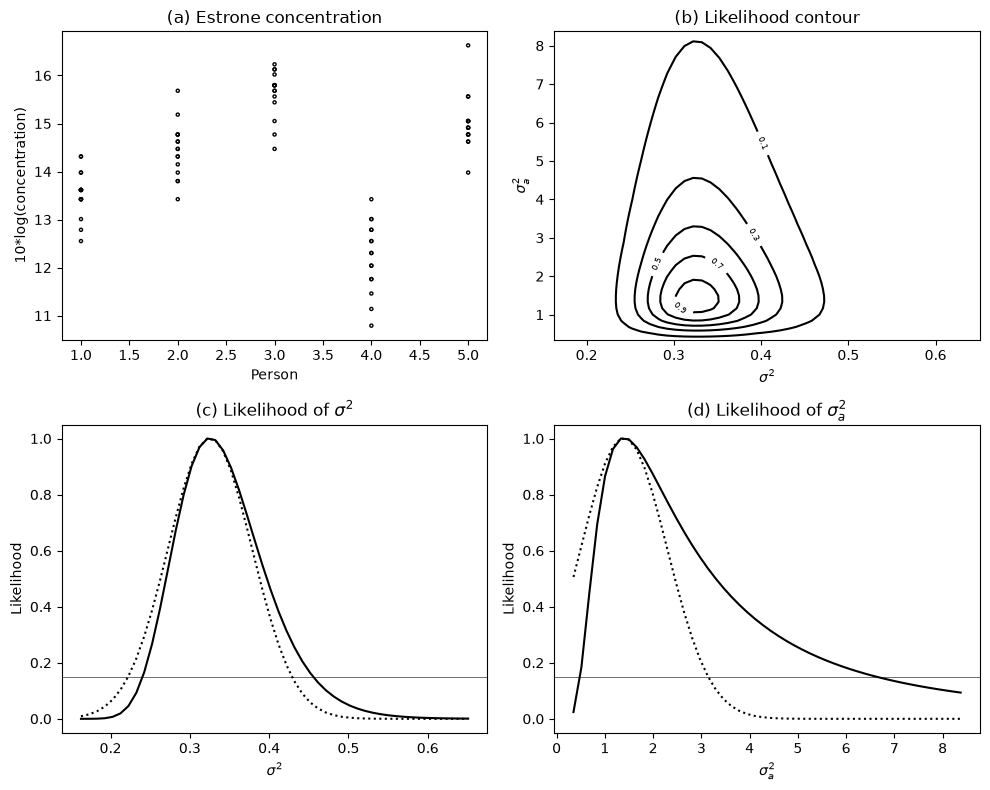

[[3.54084336e+02 7.79495764e-02]
 [7.79495764e-02 1.24719322e+00]]
[[ 2.82422479e-03 -1.76514050e-04]
 [-1.76514050e-04  8.01811413e-01]]
Standard errors= [0.05314344 0.89543923]


In [6]:
y = np.loadtxt(DATA / "random.dat")  # 16 rows (replicates) by 5 columns (persons)
y = y.ravel(order="F")  # stack the columns
y = 10 * np.log10(y)
x = np.repeat(np.arange(1, 6), 16)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
ax.scatter(x, y, s=5, facecolors="none", edgecolors="k")
ax.set_xlabel("Person")
ax.set_ylabel("10*log(concentration)")
ax.set_title("(a) Estrone concentration")

m = 5
n = 16
SST = np.sum((y - y.mean()) ** 2)  # 137.672
group_means = np.array([y[x == g].mean() for g in range(1, 6)])
SSE = np.sum((y - group_means[x - 1]) ** 2)  # 24.40768 with df=75 (residuals of y ~ factor(x))
SSA = SST - SSE

se = SSE / (m * (n - 1))  # 0.325
sa = (SSA / m - se) / n   # 1.395

np_ = 50
ssa = np.linspace(sa / 4, sa * 6, np_)
sse = np.linspace(se / 2, se * 2, np_)


def fun1(sa, se):  # -2*log-likelihood
    return m * ((n - 1) * np.log(se) + np.log(se + n * sa)) + SSE / se + SSA / (se + n * sa)


loglik1 = fun1(ssa[None, :], sse[:, None])  # rows: sigma^2 (sse), columns: sigma_a^2 (ssa)
loglik1 = -loglik1 / 2
loglik1 = loglik1 - loglik1.max()
lik1 = np.exp(loglik1)

ax = axes[1]
cs = ax.contour(sse, ssa, lik1.T, levels=np.arange(.1, 1, .2), colors="k")
ax.clabel(cs, fontsize=6)
ax.set_xlabel(r"$\sigma^2$")
ax.set_ylabel(r"$\sigma_a^2$")
ax.set_title("(b) Likelihood contour")

# Profile
likse = lik1.max(axis=1)
likse = likse / likse.max()  # normalize to max=one
ax = axes[2]
ax.plot(sse, likse, "k-")
ax.set_xlabel(r"$\sigma^2$")
ax.set_ylabel("Likelihood")
ax.set_title(r"(c) Likelihood of $\sigma^2$")

# normal approx
sd = .053
nlike = stats.norm.pdf(sse, se, sd)
nlike = nlike / nlike.max()
ax.plot(sse, nlike, "k:", lw=1.5)
ax.axhline(.15 * likse.max(), color="k", lw=0.4)
inside = sse[likse > .15 * likse.max()]
print(inside.min(), inside.max())

# Profile likelihood
liksa = lik1.max(axis=0)
liksa = liksa / liksa.sum() / (ssa[1] - ssa[0])
liksa = liksa / liksa.max()
ax = axes[3]
ax.plot(ssa, liksa, "k-")
ax.set_xlabel(r"$\sigma_a^2$")
ax.set_ylabel("Likelihood")
ax.set_title(r"(d) Likelihood of $\sigma_a^2$")
ax.axhline(.15 * liksa.max(), color="k", lw=0.4)
inside = ssa[liksa > .15 * liksa.max()]
print(inside.min(), inside.max())
print(np.sum(liksa[liksa > .15 * liksa.max()] * (ssa[1] - ssa[0])))

# normal approx
sd = .895
nlike = stats.norm.pdf(ssa, sa, sd)
nlike = nlike / nlike.max()
ax.plot(ssa, nlike, "k:", lw=1.5)

fig.tight_layout()
plt.show()

# Fisher information and covariance matrix:
mse = SSE / m / (n - 1)
msa = SSA / m
ii = np.zeros((2, 2))
ii[0, 0] = m * (n - 1) / 2 / mse ** 2 + m / 2 / msa ** 2
ii[0, 1] = m * n / 2 / msa ** 2
ii[1, 0] = ii[0, 1]
ii[1, 1] = m * n ** 2 / 2 / msa ** 2
print(ii)
print(np.linalg.inv(ii))
print("Standard errors=", np.sqrt(np.diag(np.linalg.inv(ii))))

## Section 9.10 (`SEC9-10A.R`)

Logistic model.

In [7]:
x, y = np.loadtxt(DATA / "surgery.dat", unpack=True)
n = len(y)

# glm
x0 = x - x.mean()
xglm = sm.GLM(y, sm.add_constant(x0), family=sm.families.Binomial()).fit()

# Computing covariance matrix:
X = np.column_stack([np.ones(n), x0])  # design matrix
p = xglm.fittedvalues                   # fitted probabilities
W = p * (1 - p)                         # weight vector

XW = X * W[:, None]
XWX = XW.T @ X
print("The covariance matrix:")
print(np.linalg.inv(XWX))

print("From GLM")
print(xglm.cov_params())

The covariance matrix:
[[ 0.13520899 -0.00627764]
 [-0.00627764  0.00526934]]
From GLM
[[ 0.13520899 -0.00627764]
 [-0.00627764  0.00526934]]
